##### Which consumer finance product should a Digital Retail Bank launch first, how large is Pakistan's consumer finance market, who is currently serving it, and how has inflation affected its real growth?

# Pakistan Consumer Finance Product Analysis

#### Recommending a Launch Product for Pakistan’s Digital Retail Bank

**Prepared by:** Zujaja  
**Tools Used:** Python, Pandas, NumPy, Plotly, Power BI

## Project Overview

This project analyses Pakistan's consumer finance market to identify and recommend the most suitable lending product for a **Digital Retail Bank (DRB)** to launch

The analysis begins with an Excel workbook containing bank-wise consumer finance data, year-wise product data and annual inflation rates. Using Python, the data was cleaned, validated and enriched with derived features such as **YoY growth, CAGR, inflation-adjusted (real) growth, market share, consumer finance share of advances, volatility** and a weighted **DRB Product Fit Score**. The processed data was exported as **ready-to-visualize CSV datasets**

## Dataset Note

This project uses a custom-built dataset developed for analytical purposes.

- **Bank-wise figures** (advances, total assets, total deposits and consumer finance) are compiled for each bank for **2020–2025**.
- **Product-level data** is available on a year-wise basis, not bank-wise, so product mix cannot be analysed for individual banks.
- All values are in **PKR billion** and are **nominal** unless stated otherwise; real values are calculated using the annual inflation rate.

The dataset covers **39 banks** for **2020–2025**. It is intended to support exploratory analysis and demonstrate a data-driven approach to product selection, rather than to represent official statistics.

## Dataset Overview

The original workbook (**Personal_Loans_Estimation.xlsx**) consists of three worksheets that were cleaned, processed and combined for analysis and visualization.

### Sheet 1: Data
Bank-level information for 39 banks, 2020–2025.

| Column | Description |
|--------|-------------|
| **Year** | Analysis year (2020–2025). |
| **Bank** | Name of the bank. |
| **Bank Type** | Conventional + Islamic Banking, Full Islamic, Foreign Commercial, Microfinance Bank, Digital Bank or Islamic Digital Bank. |
| **Advances (PKR Bn)** | Bank's total loan book. |
| **Total Assets (PKR Bn)** | Bank's total assets. |
| **Total Deposits (PKR Bn)** | Bank's total deposits. |
| **Cunsumer Finance (PKR bn)** | Bank's consumer finance portfolio (renamed to `Consumer_Finance_PKR_Bn`). |

---

### Sheet 2: Year wise product data
Industry-wide consumer finance by product, 2020–2025.

| Column | Description |
|--------|-------------|
| **Year** | Analysis year (2020–2025). |
| **Personal_Loans** | Unsecured loans to individuals (PKR Bn). |
| **Home_Finance** | Loans for buying, building or renovating a house (PKR Bn). |
| **Auto_Financ** | Car and motorcycle loans (PKR Bn) (renamed to `Auto_Finance`). |
| **Credit_Card_Financing** | Revolving credit through credit cards (PKR Bn). |

---

### Sheet 3: Inflation rate
**Average annual inflation rate** for Pakistan (2020–2025), used to convert nominal values into real values (2020 prices).

The worksheets were cleaned, merged and transformed using Python to create **ready-to-visualize CSV datasets** for the dashboard.

## Data Preparation & Analysis Workflow

The analysis follows a structured workflow:

1. Load the original Excel workbook and its worksheets.
2. Standardize column names.
3. Check missing values, duplicates and negative values.
4. Validate years and bank records.
5. Analyse product growth (YoY growth and CAGR).
6. Analyse who serves the market (top banks, market share, concentration).
7. Measure consumer finance focus by bank and bank type.
8. Adjust for inflation (price index, real values, real CAGR).
9. Compare products and build the DRB Product Fit Score.
10. Export the processed datasets as CSV files.
11. Final recommendation.

# Part B: Load & inspect

## Load the Datasets

The three worksheets are loaded into their own DataFrames: `bank_df` (bank data), `inflation_df` (inflation rates) and `product_df` (product data). Their dimensions are printed to confirm that all data was loaded correctly.

In [1]:
import pandas as pd
import numpy as np

file_path = "Personal_Loans_Estimation.xlsx"

bank_df = pd.read_excel(file_path, sheet_name="Data")
inflation_df = pd.read_excel(file_path, sheet_name="Inflation rate ")
product_df = pd.read_excel(file_path, sheet_name="Year wise product data")

print("Bank Data:", bank_df.shape)
print("Inflation Data:", inflation_df.shape)
print("Product Data:", product_df.shape)

Bank Data: (234, 7)
Inflation Data: (6, 2)
Product Data: (6, 5)


#### Outcome

| Dataset | Rows | Columns |
|---------|------|---------|
| Bank Data | 234 | 7 |
| Inflation Data | 6 | 2 |
| Product Data | 6 | 5 |

All three datasets were loaded with the expected dimensions (39 banks × 6 years, and 6 years of product and inflation data).

## Standardize Column Names

Extra spaces are removed from column names, and misspelt columns are corrected:
- **Cunsumer Finance (PKR bn)** → `Consumer_Finance_PKR_Bn`
- **Auto_Financ** → `Auto_Finance`

In [2]:
bank_df.columns = bank_df.columns.str.strip()

bank_df.rename(columns={
    "Cunsumer Finance (PKR bn)": "Consumer_Finance_PKR_Bn"
}, inplace=True)

product_df.rename(columns={
    "Auto_Financ": "Auto_Finance"
}, inplace=True)

inflation_df.columns = inflation_df.columns.str.strip()

print(bank_df.columns.tolist())
print(product_df.columns.tolist())

['Year', 'Bank', 'Bank Type', 'Advances (PKR Bn)', 'Total Assets (PKR Bn)', 'Total Deposits (PKR Bn)', 'Consumer_Finance_PKR_Bn']
['Year', 'Personal_Loans', 'Home_Finance', 'Auto_Finance', 'Credit_Card_Financing']


#### Outcome

Column names are now clean and consistent:

- **Bank data:** Year, Bank, Bank Type, Advances (PKR Bn), Total Assets (PKR Bn), Total Deposits (PKR Bn), Consumer_Finance_PKR_Bn
- **Product data:** Year, Personal_Loans, Home_Finance, Auto_Finance, Credit_Card_Financing

## Check for Missing Values and Duplicates

Each dataset is checked for missing values and duplicate rows to ensure the data is complete and that totals and averages are not distorted.

In [3]:
for name, df in {
    "Bank": bank_df,
    "Inflation": inflation_df,
    "Products": product_df
}.items():

    print(f"\n{name} DATA")
    print("Missing Values:\n", df.isnull().sum())
    print("Duplicate Rows:", df.duplicated().sum())


Bank DATA
Missing Values:
 Year                       0
Bank                       0
Bank Type                  0
Advances (PKR Bn)          0
Total Assets (PKR Bn)      0
Total Deposits (PKR Bn)    0
Consumer_Finance_PKR_Bn    0
dtype: int64
Duplicate Rows: 0

Inflation DATA
Missing Values:
 Year                  0
Avg_Inflation_Rate    0
dtype: int64
Duplicate Rows: 0

Products DATA
Missing Values:
 Year                     0
Personal_Loans           0
Home_Finance             0
Auto_Finance             0
Credit_Card_Financing    0
dtype: int64
Duplicate Rows: 0


#### Outcome

No missing values and no duplicate records were found in any dataset.

## Validate Years and Bank Records

The years in all three datasets are checked to confirm they cover the same period, and each bank is checked to appear exactly once per year.

In [4]:
print("Bank Years:", sorted(bank_df["Year"].unique()))
print("Product Years:", sorted(product_df["Year"].unique()))
print("Inflation Years:", sorted(inflation_df["Year"].unique()))

print("\nTotal Banks:", bank_df["Bank"].nunique())

print("\nBanks per Year:")
print(bank_df.groupby("Year")["Bank"].nunique())

print("\nDuplicate Bank-Year Records:",
      bank_df.duplicated(["Year", "Bank"]).sum())

Bank Years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Product Years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Inflation Years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Total Banks: 39

Banks per Year:
Year
2020    39
2021    39
2022    39
2023    39
2024    39
2025    39
Name: Bank, dtype: int64

Duplicate Bank-Year Records: 0


#### Outcome

- All three datasets cover **2020–2025**, so they can be compared year by year.
- There are **39 banks**, and all 39 appear in **every year**.
- There are **no duplicate bank-year records**.

## Validate Product Data

Summary statistics are reviewed for the four products, and the data is checked for negative values.

In [5]:
product_columns = [
    "Personal_Loans",
    "Home_Finance",
    "Auto_Finance",
    "Credit_Card_Financing"
]

print(product_df[product_columns].describe().round(2))

print("\nNegative Values:")
print((product_df[product_columns] < 0).sum())

print("\nProduct Data by Year:")
print(product_df.to_string(index=False))

       Personal_Loans  Home_Finance  Auto_Finance  Credit_Card_Financing
count            6.00          6.00          6.00                   6.00
mean           270.49        182.50        291.60                 102.03
std             20.48         48.66         49.78                  36.90
min            239.00         93.70        235.45                  50.20
25%            265.42        169.50        252.56                  78.58
50%            267.95        206.00        287.75                 108.00
75%            279.17        210.25        330.06                 120.18
max            300.54        220.30        353.63                 153.00

Negative Values:
Personal_Loans           0
Home_Finance             0
Auto_Finance             0
Credit_Card_Financing    0
dtype: int64

Product Data by Year:
 Year  Personal_Loans  Home_Finance  Auto_Finance  Credit_Card_Financing
 2020         282.890          93.7        256.50                   50.2
 2021         300.543         158.0

#### Outcome

No negative values were found. In 2025, **auto finance** is the largest product (PKR 319.0 bn), followed by **personal loans** (PKR 264.6 bn), **home finance** (PKR 220.3 bn) and **credit card financing** (PKR 153.0 bn). Auto finance shows the widest range (PKR 235.5–353.6 bn), indicating high volatility.

# Part C: Product growth

## Calculate Year-on-Year Growth

The percentage change from the previous year is calculated for each product.

In [27]:
products = [
    "Personal_Loans",
    "Auto_Finance",
    "Home_Finance",
    "Credit_Card_Financing"
]

for col in products:
    product_analysis[f"{col}_YoY_%"] = (
        product_analysis[col].pct_change() * 100
    )

product_analysis.round(2)

,Year,Personal_Loans,Home_Finance,Auto_Finance,Credit_Card_Financing,Personal_Loans_YoY_%,Auto_Finance_YoY_%,Home_Finance_YoY_%,Credit_Card_Financing_YoY_%
0,2020,282.89,93.7,256.50,50.2,NaN,NaN,NaN,NaN
1,2021,300.54,158.0,353.63,71.0,6.24,37.87,68.62,41.43
2,2022,267.90,211.0,333.75,101.3,-10.86,-5.62,33.54,42.68
3,2023,268.00,208.0,251.25,114.7,0.04,-24.72,-1.42,13.23
4,2024,239.00,204.0,235.45,122.0,-10.82,-6.29,-1.92,6.36
5,2025,264.60,220.3,319.00,153.0,10.71,35.49,7.99,25.41


#### Outcome

| Product | 2021 | 2022 | 2023 | 2024 | 2025 |
|---------|------|------|------|------|------|
| Personal Loans | 6.2% | −10.9% | 0.0% | −10.8% | 10.7% |
| Auto Finance | 37.9% | −5.6% | −24.7% | −6.3% | 35.5% |
| Home Finance | 68.6% | 33.5% | −1.4% | −1.9% | 8.0% |
| Credit Card Financing | 41.4% | 42.7% | 13.2% | 6.4% | 25.4% |

Values for 2020 are blank because there is no prior year to compare with. **Credit card financing grew in every year**, while all other products contracted in at least two years.

## Calculate Growth Rates (CAGR)

The compound annual growth rate is calculated for each product over 2020–2025:

CAGR = (End value ÷ Start value)^(1 ÷ Years) − 1

In [8]:
cagr_results = {}

for col in products:
    start_value = product_analysis.iloc[0][col]
    end_value = product_analysis.iloc[-1][col]

    cagr = ((end_value / start_value) ** (1/5) - 1) * 100

    cagr_results[col] = round(cagr, 2)

cagr_df = pd.DataFrame(
    list(cagr_results.items()),
    columns=["Product", "CAGR_%"]
)

cagr_df.sort_values("CAGR_%", ascending=False)

,Product,CAGR_%
3,Credit_Card_Financing,24.97
2,Home_Finance,18.65
1,Auto_Finance,4.46
0,Personal_Loans,-1.33


#### Outcome


Credit card financing is the fastest-growing product, while **personal loans are the only product that declined** in nominal terms.

## Visualize Annual Growth

The YoY growth columns are selected and plotted as a line chart to compare how each product's growth changed over time.

In [9]:
import plotly.express as px

In [10]:
growth_columns = [col for col in product_analysis.columns if "YoY" in col]

In [11]:
print(growth_columns)

['Personal_Loans_YoY_%', 'Auto_Finance_YoY_%', 'Home_Finance_YoY_%', 'Credit_Card_Financing_YoY_%']


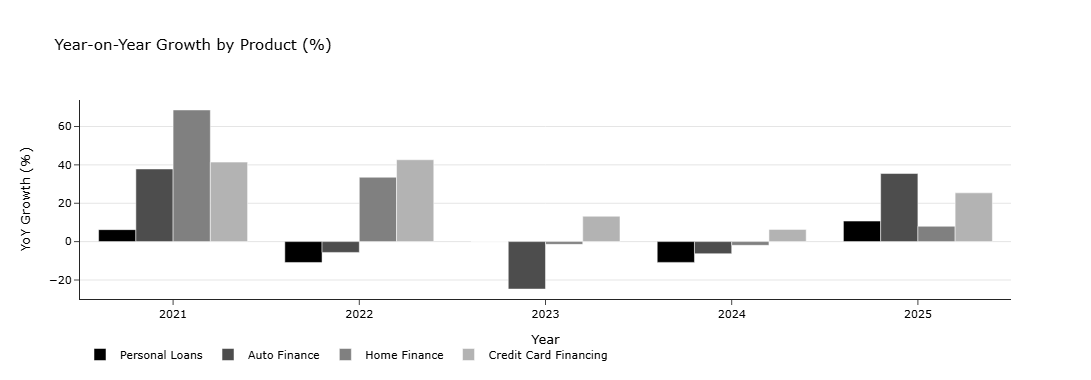

In [34]:
import plotly.graph_objects as go

cols = {
    "Personal_Loans_YoY_%": ("Personal Loans", "#000000"),
    "Auto_Finance_YoY_%": ("Auto Finance", "#4D4D4D"),
    "Home_Finance_YoY_%": ("Home Finance", "#808080"),
    "Credit_Card_Financing_YoY_%": ("Credit Card Financing", "#B3B3B3")
}

data = product_analysis.dropna(subset=list(cols))

fig = go.Figure([
    go.Bar(x=data["Year"].astype(str), y=data[c], name=n, marker_color=color)
    for c, (n, color) in cols.items()
])

fig.update_layout(
    title="Year-on-Year Growth by Product (%)",
    barmode="group", template="simple_white",
    xaxis=dict(title="Year"),
    yaxis=dict(title="YoY Growth (%)", showgrid=True, gridcolor="#E5E5E5"),
    width=700, height=380,
    legend=dict(orientation="h", y=-0.2),
    font=dict(color="black", size=11)
)

fig.show()

#### Outcome

- **2021 was the strongest year for all products.** Home finance grew the most (+68.6%).
- **2022–2024 was a period of slowdown.** High inflation and interest rates hit auto finance hardest, with its biggest drop in 2023 (−24.7%).
- **Credit card financing was the only product that grew in every year.**
- **2025 saw a recovery across all products.** Auto finance bounced back the most (+35.5%) as interest rates fell.

**Key takeaway:** Auto finance is the most volatile product, while personal loans are the most stable, making them a lower-risk starting product for a Digital Retail Bank.

# Part D: Who serves the market

## Latest Year Bank Performance (2025)

Banks are ranked by consumer finance in 2025, alongside their advances, total assets and total deposits.

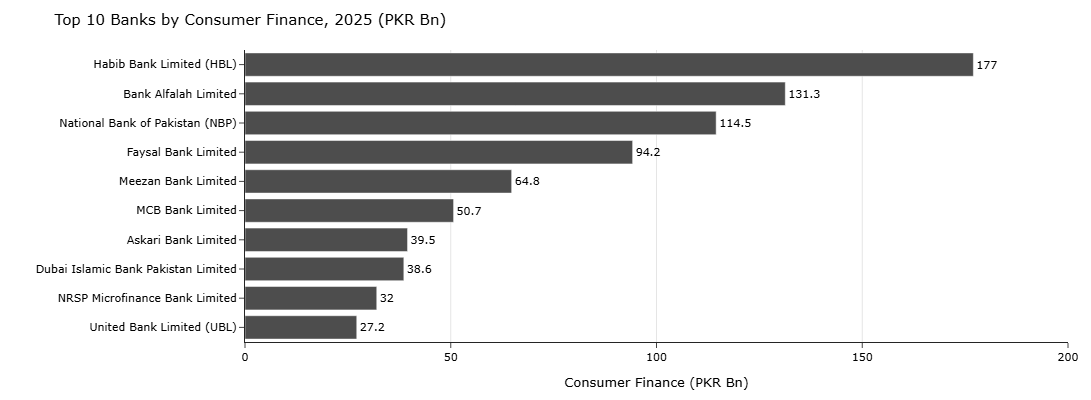

In [37]:
import plotly.graph_objects as go

top10 = (bank_df[bank_df["Year"] == 2025]
         .nlargest(10, "Consumer_Finance_PKR_Bn")
         .sort_values("Consumer_Finance_PKR_Bn"))

fig = go.Figure(go.Bar(
    x=top10["Consumer_Finance_PKR_Bn"],
    y=top10["Bank"],
    orientation="h",
    marker_color="#4D4D4D",
    text=top10["Consumer_Finance_PKR_Bn"].round(1),
    textposition="outside",
    hovertemplate="%{y}<br>PKR %{x:.1f} Bn<extra></extra>"
))

fig.update_layout(
    title="Top 10 Banks by Consumer Finance, 2025 (PKR Bn)",
    template="simple_white",
    xaxis=dict(title="Consumer Finance (PKR Bn)", range=[0, 200],
               showgrid=True, gridcolor="#E5E5E5"),
    yaxis_title="",
    width=700, height=400,
    margin=dict(l=50, r=20, t=50, b=50),
    showlegend=False,
    font=dict(size=11, color="black")
)

fig.show()

#### Outcome

**Habib Bank Limited (HBL)** is the largest consumer lender (PKR 177.0 bn), followed by **Bank Alfalah** (PKR 131.3 bn) and **NBP** (PKR 114.5 bn). **NRSP Microfinance Bank** (PKR 32.0 bn) is the only microfinance bank in the top 10.

## Market Share of Top Banks

Each bank's share of total consumer finance in 2025 is calculated, and the market share of the top 10 banks is shown as a pie chart.

## Calculate Consumer Finance Share of Advances

This ratio shows how much of a bank’s total lending is allocated to consumer finance, highlighting its focus on consumer lending 

In [14]:
latest["Consumer_Finance_Share_%"] = (
    latest["Consumer_Finance_PKR_Bn"] /
    latest["Advances (PKR Bn)"]
) * 100

latest.sort_values(
    "Consumer_Finance_Share_%",
    ascending=False
)[["Bank", "Consumer_Finance_Share_%"]].head(10)

,Bank,Consumer_Finance_Share_%
179,NRSP Microfinance Bank Limited,81.269036
221,Easypaisa Bank Limited,68.936496
191,ABHI Microfinance Bank Limited,36.261981
197,LOLC Microfinance Bank Limited,32.645740
209,Halan Microfinance Bank Limited,26.038781
185,HBL Microfinance Bank,18.000000
113,Dubai Islamic Bank Pakistan Limited,16.266330
35,Bank Alfalah Limited,11.417391
167,Mobilink Microfinance Bank Limited (JazzCash),10.990000
125,Faysal Bank Limited,10.385888




#### Outcome

- **Small digital and microfinance banks are the most focused on consumer finance.** NRSP Microfinance Bank (81.3%), Easypaisa Bank (68.9%), ABHI (36.3%) and LOLC (32.6%) give a large share of their advances to consumer lending.
- **Large banks treat consumer finance as a side business.** Even the most focused, Bank Alfalah (11.4%) and Faysal Bank (10.4%), give only about a tenth of their advances, and NBP gives just 6.2%.

**What this means for a DRB:** A business built mainly on consumer lending is proven to work, while large banks leave this segment underserved.

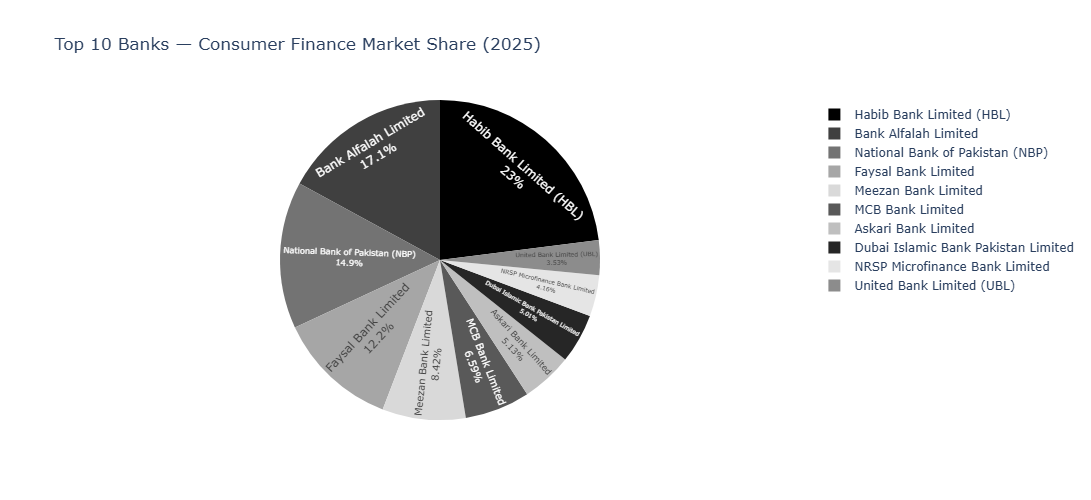

In [38]:
latest["Market_Share_%"] = latest["Consumer_Finance_PKR_Bn"] / latest["Consumer_Finance_PKR_Bn"].sum() * 100
top10_share = latest.nlargest(10, "Market_Share_%")

fig = px.pie(
    top10_share, names="Bank", values="Market_Share_%",
    title="Top 10 Banks — Consumer Finance Market Share (2025)",
    color_discrete_sequence=["#000000", "#404040", "#737373", "#A6A6A6", "#D9D9D9",
                            "#595959", "#BFBFBF", "#262626", "#E5E5E5", "#8C8C8C"]
)

fig.update_layout(width=800, height=500)
fig.update_traces(textinfo="percent+label", textposition="inside",
                  marker=dict(line=dict(width=0)))
fig.show()

#### Outcome

**HBL holds about 18.5%** of the market, followed by Bank Alfalah (13.7%) and NBP (11.9%).

## Bank-Level Consumer Finance Growth (2020–2025)

This analysis calculates the Compound Annual Growth Rate (CAGR) of consumer finance for each bank between 2020 and 2025 to identify the fastest-growing banks

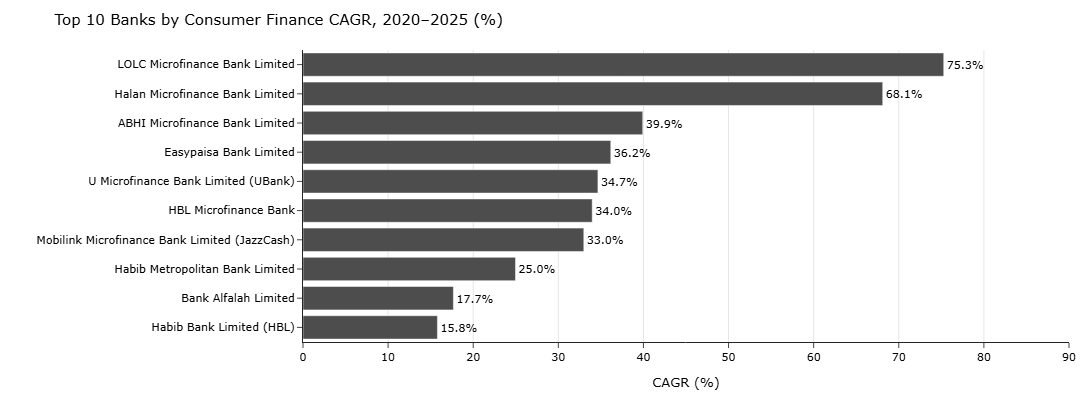

In [53]:
cf = bank_df.pivot(index="Bank", columns="Year", values="Consumer_Finance_PKR_Bn")
bank_cagr = cf[(cf[2020] > 0) & (cf[2025] >= 1)].copy()
bank_cagr["CAGR_%"] = ((bank_cagr[2025] / bank_cagr[2020]) ** 0.2 - 1) * 100

top10_cagr = bank_cagr.nlargest(10, "CAGR_%").sort_values("CAGR_%").reset_index()

fig = go.Figure(go.Bar(
    x=top10_cagr["CAGR_%"], y=top10_cagr["Bank"], orientation="h",
    marker_color="#4D4D4D",
    text=top10_cagr["CAGR_%"].round(1).astype(str) + "%",
    textposition="outside",
    hovertemplate="%{y}<br>CAGR %{x:.1f}%<extra></extra>"
))

fig.update_layout(
    title="Top 10 Banks by Consumer Finance CAGR, 2020–2025 (%)",
    template="simple_white",
    xaxis=dict(title="CAGR (%)", range=[0, 90], showgrid=True, gridcolor="#E5E5E5"),
    yaxis_title="", width=700, height=400,
    margin=dict(l=50, r=20, t=50, b=50),
    showlegend=False, font=dict(size=11, color="black")
)

fig.show()

#### Outcomes

- **LOLC Microfinance Bank** leads with 75.3% CAGR, followed by **Halan Microfinance Bank (68.1%)**.
- Microfinance banks dominate the top 10 rankings.


## Market Concentration (2025)

The combined market share of the top 5 and top 10 banks is calculated to measure how concentrated the market is.

In [16]:
latest["Market_Share_%"] = latest["Consumer_Finance_PKR_Bn"] / latest["Consumer_Finance_PKR_Bn"].sum() * 100

ranked = latest.sort_values("Consumer_Finance_PKR_Bn", ascending=False)["Market_Share_%"]
top_5_share, top_10_share = ranked.head(5).sum(), ranked.head(10).sum()

concentration = pd.DataFrame({
    "Category": ["Top 5 Banks", "Top 10 Banks", "Other Banks"],
    "Market Share (%)": [top_5_share, top_10_share, 100 - top_10_share]
})

fig = px.bar(concentration, x="Category", y="Market Share (%)", color="Category",
             text_auto=".2f", title="Consumer Finance Market Concentration — 2025",
             color_discrete_sequence=["#000000", "#737373", "#BFBFBF"], template="simple_white")

fig.update_traces(textposition="outside")
fig.update_layout(width=600, height=500, showlegend=False, xaxis_title="")
fig.show()

for cat, val in concentration.values:
    print(f"{cat} Market Share: {val:.2f}%")

Top 5 Banks Market Share: 60.68%
Top 10 Banks Market Share: 80.29%
Other Banks Market Share: 19.71%


#### Outcome

The consumer finance market is **highly concentrated**: the top 10 banks control about four-fifths of it.

# Part E: Inflation & real growth

## Average Inflation Rate (2020–2025)

Annual inflation is converted to percentages and plotted to show the price environment over the analysis period.

In [39]:
import plotly.express as px

inf = inflation_df.copy()
inf["inflation_pct"] = inf["Avg_Inflation_Rate"] * 100

print(inf[["Year", "inflation_pct"]].round(2))



   Year  inflation_pct
0  2020           9.74
1  2021           9.50
2  2022          19.87
3  2023          30.77
4  2024          12.63
5  2025           3.55


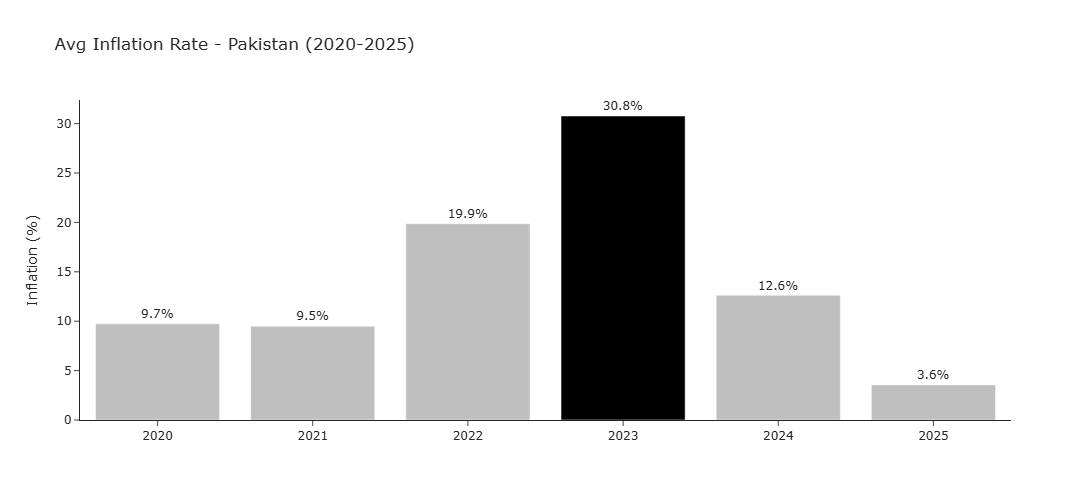

In [40]:

colors = ["#000000" if v == inf["inflation_pct"].max() else "#BFBFBF" for v in inf["inflation_pct"]]

fig = px.bar(inf, x="Year", y="inflation_pct",
             text=(inf["inflation_pct"] + 1e-9).round(1).astype(str) + "%",
             title="Avg Inflation Rate - Pakistan (2020-2025)",
             template="simple_white")

fig.update_traces(marker_color=colors, textposition="outside")
fig.update_layout(yaxis_title="Inflation (%)", xaxis_title="", width=800, height=500,
                  xaxis=dict(tickmode="linear", dtick=1))
fig.show()

#### Outcome


Inflation peaked at **30.8% in 2023** before falling sharply to **3.6% in 2025**. Over the full period, prices roughly **doubled**.

## Nominal vs Real Growth


Prices roughly doubled between 2020 and 2025, so each product's value is adjusted to 2020 prices to compare nominal and real growth.

In [43]:
products = ["Personal_Loans", "Auto_Finance", "Home_Finance", "Credit_Card_Financing"]

inflation = inflation_df.set_index("Year")["Avg_Inflation_Rate"]
price_index = (1 + inflation).cumprod() / (1 + inflation.loc[2020])

nominal = product_df.set_index("Year")[products]
real = nominal.div(price_index, axis=0)

cagr = pd.DataFrame({
    "Nominal CAGR": (nominal.iloc[-1] / nominal.iloc[0]) ** 0.2 * 100 - 100,
    "Real CAGR (2020 prices)": (real.iloc[-1] / real.iloc[0]) ** 0.2 * 100 - 100
})

cagr.index = cagr.index.str.replace("_", " ")
cagr = cagr.sort_values("Nominal CAGR")

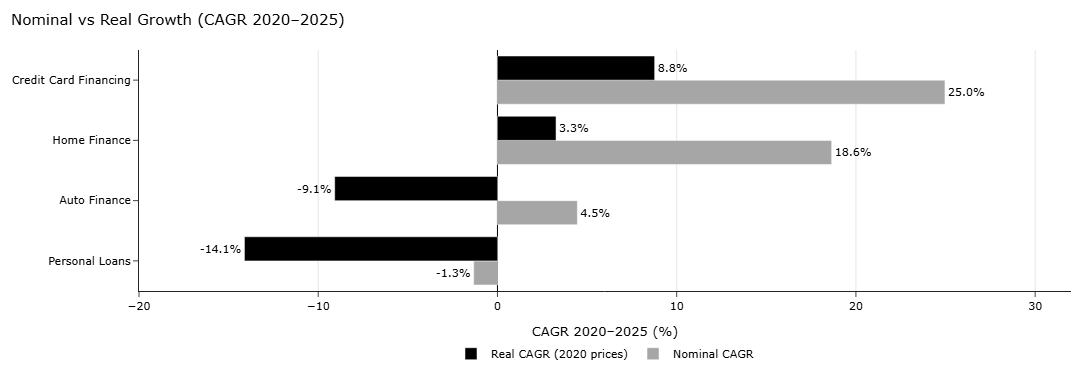

In [44]:
fig = go.Figure([
    go.Bar(y=cagr.index, x=cagr[c], name=c, orientation="h",
           marker_color=color, text=cagr[c].round(1).astype(str) + "%",
           textposition="outside")
    for c, color in [("Nominal CAGR", "#A6A6A6"), ("Real CAGR (2020 prices)", "#000000")]
])

fig.update_layout(
    title=dict(text="Nominal vs Real Growth (CAGR 2020–2025)", x=0.01,
               font=dict(size=15, color="black")),
    barmode="group", template="simple_white", width=700, height=380,
    xaxis=dict(title="CAGR 2020–2025 (%)", range=[-20, 32],
               showgrid=True, gridcolor="#E5E5E5",
               zeroline=True, zerolinecolor="black", zerolinewidth=1),
    legend=dict(orientation="h", y=-0.2, x=0.5, xanchor="center",
                yanchor="top", traceorder="reversed"),
    font=dict(size=11, color="black"),
    margin=dict(l=50, r=20, t=50, b=70)
)

fig.show()

#### Outcome

| Product | Nominal CAGR | Real CAGR | 2020 value | 2025 value |
|---------|--------------|-----------|------------|--------------------------|
| Credit Card Financing | 25.0% | 8.8% | 50.2 | 76.4 |
| Home Finance | 18.6% | 3.3% | 93.7 | 110.0 |
| Auto Finance | 4.5% | −9.1% | 256.5 | 159.4 |
| Personal Loans | −1.3% | −14.1% | 282.9 | 132.2 |

*Values in PKR billion.*

- **The total market shrank in real terms.** Adjusted to 2020 prices, it fell from PKR 683.3 bn to about PKR 478.0 bn, a real decline of about 6.9% a year.
- **Only credit card financing and home finance grew after inflation.**
- **Personal loans had the largest real decline.** They lost more than half of their real value.



Only **credit card financing and home finance** grew in real terms. **Personal loans fell from PKR 282.9 bn to PKR 132.2 bn** in 2020 prices, losing more than half of their real value.

**Key takeaway:** The fall in personal loans reflects reduced supply due to tighter regulation and high interest rates, not weak demand. Once rates eased in 2025, personal lending started growing again.

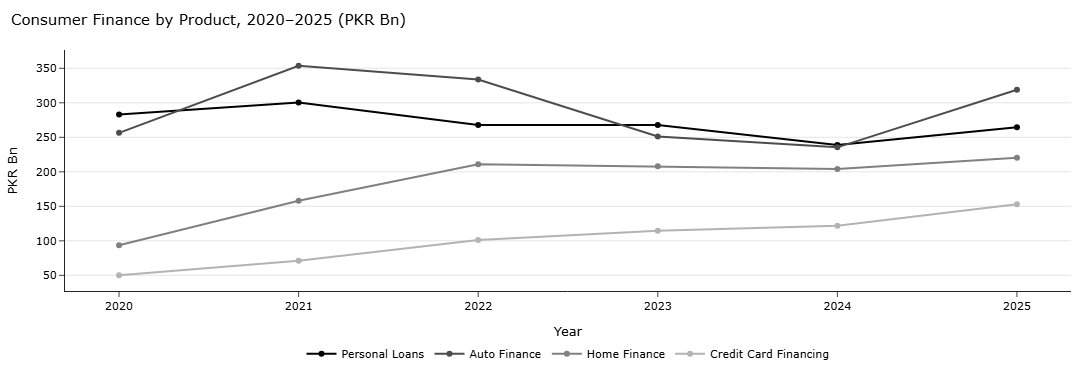

In [45]:
import plotly.graph_objects as go

products_plot = {
    "Personal_Loans": ("Personal Loans", "#000000"),
    "Auto_Finance": ("Auto Finance", "#4D4D4D"),
    "Home_Finance": ("Home Finance", "#808080"),
    "Credit_Card_Financing": ("Credit Card Financing", "#B3B3B3")
}

fig = go.Figure([
    go.Scatter(
        x=product_analysis["Year"], y=product_analysis[col],
        mode="lines+markers", name=name,
        line=dict(color=color, width=2),
        hovertemplate=f"{name}<br>Year: %{{x}}<br>PKR %{{y:.1f}} Bn<extra></extra>"
    )
    for col, (name, color) in products_plot.items()
])

fig.update_layout(
    title=dict(text="Consumer Finance by Product, 2020–2025 (PKR Bn)", x=0.01),
    template="simple_white", width=700, height=380,
    xaxis=dict(title="Year", tickmode="linear", dtick=1),
    yaxis=dict(title="PKR Bn", showgrid=True, gridcolor="#E5E5E5"),
    legend=dict(orientation="h", y=-0.2, x=0.5, xanchor="center"),
    font=dict(size=11, color="black"),
    margin=dict(l=50, r=20, t=50, b=70)
)

fig.show()

#### Outcome

| Product | 2020 | 2025 | Change |
|---------|------|------|--------|
| Personal Loans | 282.9 | 264.6 | −6.5% |
| Auto Finance | 256.5 | 319.0 | +24.4% |
| Home Finance | 93.7 | 220.3 | +135.1% |
| Credit Card Financing | 50.2 | 153.0 | +204.8% |

- **Personal Loans:** Peaked at PKR 300.5 bn in 2021, declined to PKR 239.0 bn in 2024, then recovered to PKR 264.6 bn in 2025, below the 2020 level of PKR 282.9 bn.
- **Auto Finance:** Rose to PKR 353.6 bn in 2021, fell to PKR 235.5 bn in 2024, then rebounded to PKR 319.0 bn in 2025, becoming the largest product.
- **Home Finance:** Grew from PKR 93.7 bn to PKR 220.3 bn, mainly during 2021–2022, then remained broadly flat.
- **Credit Card Financing:** The only product with consistent annual growth, nearly tripling from PKR 50.2 bn to PKR 153.0 bn.

**Auto finance context:**

- **2022–2024 (Decline):** Auto financing fell sharply due to SBP regulatory restrictions, rising interest rates and soaring car prices. Shorter loan tenures, higher monthly instalments, larger down payments and reduced purchasing power made car loans unaffordable for many consumers. By December 2024, auto financing stood at around **PKR 235.45 bn**, down 6.3% from December 2023 (PKR 251.25 bn), as policy rates peaked near 22%.
- **2025 (Growth turnaround):** As the State Bank of Pakistan (SBP) cut interest rates throughout 2025 (lowering the policy rate from 22% toward 11%), car loans recovered strongly, and auto finance grew **35.5%** to PKR 319.0 bn.

# Part F: Consumer finance focus by bank type

## Consumer Finance by Bank Type (2025)

The 2025 data is grouped by bank type. For each type, consumer finance as a share of advances (**focus**) and its share of total consumer finance (**market share**) are calculated. Bank types with zero advances (Islamic Digital Banks) are excluded.

In [46]:
summary = bank_df[bank_df["Year"] == 2025].groupby("Bank Type").sum(numeric_only=True)
summary = summary[summary["Advances (PKR Bn)"] > 0]

summary["CF_%_of_Advances"] = summary["Consumer_Finance_PKR_Bn"] / summary["Advances (PKR Bn)"] * 100
summary["Market_Share_%"] = summary["Consumer_Finance_PKR_Bn"] / summary["Consumer_Finance_PKR_Bn"].sum() * 100

print(summary[["Consumer_Finance_PKR_Bn", "CF_%_of_Advances", "Market_Share_%"]].round(1))

                                Consumer_Finance_PKR_Bn  CF_%_of_Advances  \
Bank Type                                                                   
Conventional + Islamic Banking                    622.0               4.4   
Digital Bank                                       18.0              68.9   
Foreign Commercial                                  0.6               0.1   
Full Islamic                                      221.8               6.6   
Microfinance Bank                                  96.4              18.9   

                                Market_Share_%  
Bank Type                                       
Conventional + Islamic Banking            64.9  
Digital Bank                               1.9  
Foreign Commercial                         0.1  
Full Islamic                              23.1  
Microfinance Bank                         10.1  


#### Outcome

| Bank Type | Consumer Finance (PKR Bn) | % of Advances | Market Share |
|-----------|---------------------------|---------------|--------------|
| Conventional + Islamic Banking | 622.0 | 4.4% | **64.9%** |
| Full Islamic | 221.8 | 6.6% | 23.1% |
| Microfinance Bank | 96.4 | 18.9% | 10.1% |
| Digital Bank | 18.0 | **68.9%** | 1.9% |
| Foreign Commercial | 0.6 | 0.1% | 0.1% |

Conventional banks hold almost two-thirds of the market, but consumer finance is **only 4.4% of their loan books**. Digital banks are the opposite: small in size but **highly focused** on consumer lending.

## Visualize Consumer Finance as % of Advances

The bank types are sorted by their consumer finance share of advances and shown as a horizontal bar chart.

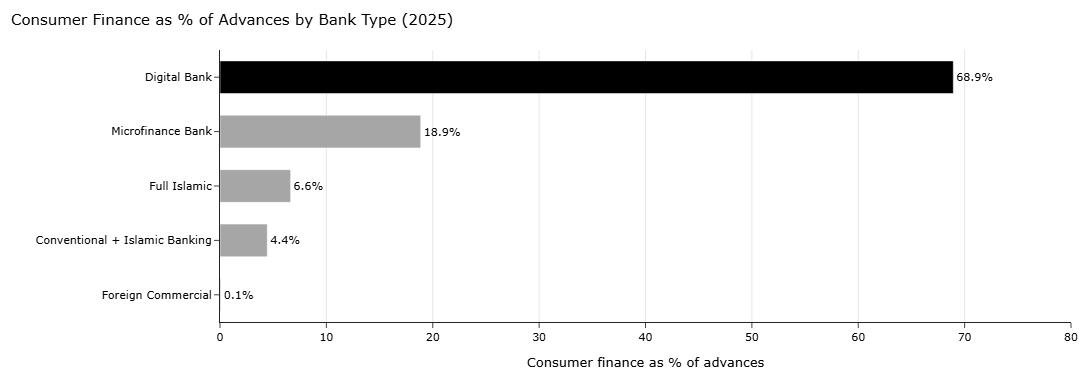

In [48]:
summary = summary.sort_values("CF_%_of_Advances")

colors = ["#000000" if v == summary["CF_%_of_Advances"].max() else "#A6A6A6"
          for v in summary["CF_%_of_Advances"]]

fig = px.bar(summary, x="CF_%_of_Advances", y=summary.index, orientation="h",
             text=summary["CF_%_of_Advances"].round(1).astype(str) + "%",
             title="Consumer Finance as % of Advances by Bank Type (2025)",
             template="simple_white")

fig.update_traces(marker_color=colors, textposition="outside", width=0.6)
fig.update_layout(
    width=700, height=380,
    title=dict(x=0.01, font=dict(size=15, color="black")),
    xaxis=dict(title="Consumer finance as % of advances", range=[0, 80],
               showgrid=True, gridcolor="#E5E5E5"),
    yaxis_title="",
    font=dict(size=11, color="black"),
    margin=dict(l=50, r=20, t=50, b=50)
)
fig.show()

#### Outcome

**The only digital bank Easypaisa (68.9%)** and **microfinance banks (18.9%)** are far more focused on consumer finance than conventional banks, showing that small-ticket digital consumer lending can sustain a dedicated business model.

# Part G: DRB product selection

## Compare the Main Lending Products

Personal loans, auto finance and home finance are compared on six measures:
- **Value 2020 / Value 2025:** size of the product.
- **CAGR (%) / Real CAGR (%):** nominal and inflation-adjusted growth.
- **Volatility (%):** standard deviation of YoY growth, used as an indicator of risk.
- **Growth 2025 (%):** strength of the recent recovery.

Credit card financing is treated as an add-on and is not included.

In [22]:

compare = ["Personal_Loans", "Auto_Finance", "Home_Finance"]

data = product_df.set_index("Year")
table = pd.DataFrame(index=compare)

table["Value_2020"] = data.loc[2020, compare]
table["Value_2025"] = data.loc[2025, compare]
table["CAGR_%"] = ((table["Value_2025"] / table["Value_2020"]) ** (1/5) - 1) * 100

table["Real_CAGR_%"] = ((real.loc[2025, compare] / real.loc[2020, compare]) ** (1/5) - 1) * 100

yoy = data[compare].pct_change() * 100
table["Volatility_%"] = yoy.std()

table["Growth_2025_%"] = yoy.loc[2025]

print(table.round(1))

                Value_2020  Value_2025  CAGR_%  Real_CAGR_%  Volatility_%  \
Personal_Loans       282.9       264.6    -1.3        -14.1           9.8   
Auto_Finance         256.5       319.0     4.5         -9.1          27.9   
Home_Finance          93.7       220.3    18.6          3.3          30.1   

                Growth_2025_%  
Personal_Loans           10.7  
Auto_Finance             35.5  
Home_Finance              8.0  


#### Outcome

| Product | 2020 | 2025 | CAGR | Real CAGR | Volatility | 2025 Growth |
|---------|------|------|------|-----------|------------|-------------|
| Personal Loans | 282.9 | 264.6 | −1.3% | −14.1% | **9.8%** | 10.7% |
| Auto Finance | 256.5 | 319.0 | 4.5% | −9.1% | 27.9% | **35.5%** |
| Home Finance | 93.7 | 220.3 | 18.6% | **3.3%** | 30.1% | 8.0% |

Personal loans are by far the **most stable** product, auto finance has the **strongest recovery**, and home finance has the **best long-term real growth**.

In consumer finance, volatility refers to the degree of fluctuation in the prices of consumer goods and services over time.

## DRB Product Fit Score

Each product is scored from **1 to 5** on five factors. Scores are listed in the order **Personal Loans, Auto Finance, Home Finance**.

| Factor | Weight | Personal | Auto | Home | Why |
|--------|--------|----------|------|------|-----|
| Digital_Easy | 25% | 5 | 3 | 1 | Personal loans work fully in an app; auto needs dealers; home needs property checks |
| Short_Tenor | 20% | 5 | 3 | 1 | Personal 1–3 years; auto ~5 years; home 15–20 years |
| Low_Risk | 20% | 4 | 2 | 2 | Volatility: 9.8%, 27.9%, 30.1% |
| Market_Gap | 20% | 5 | 3 | 4 | Personal loans lost the most real value, showing the biggest supply gap |
| Real_Growth | 15% | 2 | 2 | 4 | Real CAGR: −14.1%, −9.1%, +3.3% |

In [23]:
scores = pd.DataFrame({

    "Digital_Easy": [5, 3, 1],   # Can the product be delivered fully through an app?
    "Short_Tenor":  [5, 3, 1],   # Does the loan term match a new bank's short-term deposits?
    "Low_Risk":     [4, 2, 2],   # Is the product stable? (based on volatility)
    "Market_Gap":   [5, 3, 4],   # How underserved is the segment by existing banks?
    "Real_Growth":  [2, 2, 4],   # Growth after inflation
}, index=compare)

# each factores importance(total = 1)
weights = {"Digital_Easy": 0.25, "Short_Tenor": 0.20, "Low_Risk": 0.20,
           "Market_Gap": 0.20, "Real_Growth": 0.15}

scores["Total_Score"] = 0
for factor, w in weights.items():
    scores["Total_Score"] += scores[factor] * w

print(scores.sort_values("Total_Score", ascending=False))

                Digital_Easy  Short_Tenor  Low_Risk  Market_Gap  Real_Growth  \
Personal_Loans             5            5         4           5            2   
Auto_Finance               3            3         2           3            2   
Home_Finance               1            1         2           4            4   

                Total_Score  
Personal_Loans         4.35  
Auto_Finance           2.65  
Home_Finance           2.25  


#### Outcome

| Rank | Product | Total Score |
|------|---------|-------------|
| 1 | Personal Loans | **4.35** |
| 2 | Auto Finance | 2.65 |
| 3 | Home Finance | 2.25 |

**Personal loans score highest**, scoring 5 on digital ease, short tenor and market gap. Their only weakness is negative real growth.

## Visualize the Product Fit Score

The total scores are shown as a horizontal bar chart.

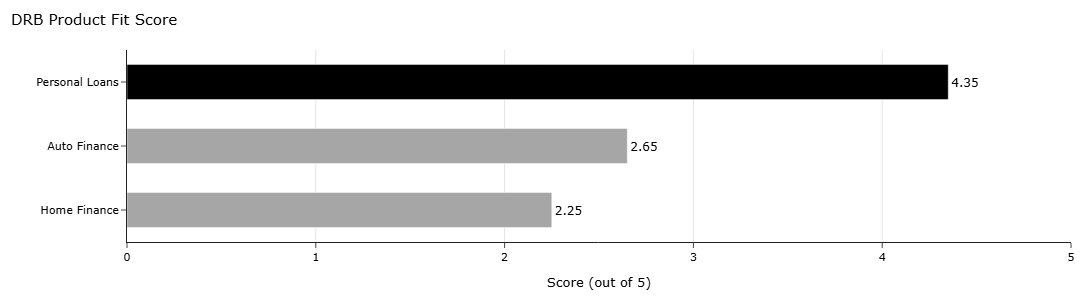

In [49]:
s = scores.sort_values("Total_Score")
s.index = s.index.str.replace("_", " ")
colors = ["#000000" if v == s["Total_Score"].max() else "#A6A6A6" for v in s["Total_Score"]]

fig = px.bar(s, x="Total_Score", y=s.index, orientation="h",
             text=s["Total_Score"].round(2), title="DRB Product Fit Score",
             template="simple_white")

fig.update_traces(marker_color=colors, textposition="outside", width=0.55,
                  textfont=dict(size=12, color="black"))
fig.update_layout(
    width=700, height=300,
    title=dict(x=0.01, font=dict(size=15, color="black")),
    xaxis=dict(title="Score (out of 5)", range=[0, 5], dtick=1,
               showgrid=True, gridcolor="#E5E5E5"),
    yaxis_title="", font=dict(size=11, color="black"),
    margin=dict(l=50, r=20, t=50, b=50)
)
fig.show()

#### Outcome

Personal loans lead clearly, scoring **1.7 points ahead** of auto finance.

## Export the Processed Datasets

The processed data is exported as two CSV files for the Power BI dashboard. Bank-level and year-level data are kept in **separate files**, because merging yearly product totals into bank rows would repeat values and inflate totals in Power BI. The two tables can be linked through the **Year** column.

- **Bank level:** adds CF YoY growth, CF share of advances, market share and the advances-to-deposits ratio. Infinite values caused by zero advances are replaced with blanks.
- **Year level:** adds product YoY growth, inflation (%) and real product values in 2020 prices.

In [50]:
bank_pbi = bank_df.rename(columns={
    "Bank Type": "Bank_Type",
    "Advances (PKR Bn)": "Advances_PKR_Bn",
    "Total Assets (PKR Bn)": "Total_Assets_PKR_Bn",
    "Total Deposits (PKR Bn)": "Total_Deposits_PKR_Bn"
}).sort_values(["Bank", "Year"]).copy()

bank_pbi["CF_YoY_Growth_%"] = bank_pbi.groupby("Bank")["Consumer_Finance_PKR_Bn"].pct_change() * 100
bank_pbi["CF_Share_of_Advances_%"] = bank_pbi["Consumer_Finance_PKR_Bn"] / bank_pbi["Advances_PKR_Bn"] * 100
bank_pbi["Market_Share_%"] = bank_pbi["Consumer_Finance_PKR_Bn"] / bank_pbi.groupby("Year")["Consumer_Finance_PKR_Bn"].transform("sum") * 100
bank_pbi["Advances_to_Deposits_%"] = bank_pbi["Advances_PKR_Bn"] / bank_pbi["Total_Deposits_PKR_Bn"] * 100
bank_pbi = bank_pbi.replace([np.inf, -np.inf], np.nan).round(2)

year_pbi = product_df.sort_values("Year").copy()
year_pbi[[f"{c}_YoY_%" for c in products]] = year_pbi[products].pct_change() * 100
year_pbi = year_pbi.merge(inflation_df, on="Year", how="left")
year_pbi["Inflation_%"] = year_pbi.pop("Avg_Inflation_Rate") * 100
year_pbi = year_pbi.merge(real.add_suffix("_Real_2020").reset_index(), on="Year", how="left").round(2)

product_pbi = scores.join(table).reset_index().rename(columns={"index": "Product"})
product_pbi["Product"] = product_pbi["Product"].str.replace("_", " ")
product_pbi = product_pbi.round(2)

bank_pbi.to_csv("PowerBI_Bank_Data.csv", index=False)
year_pbi.to_csv("PowerBI_Year_Data.csv", index=False)
product_pbi.to_csv("PowerBI_Product_Score.csv", index=False)

print("Bank data:", bank_pbi.shape)
print("Year data:", year_pbi.shape)
print("Product data:", product_pbi.shape)

Bank data: (234, 11)
Year data: (6, 14)
Product data: (3, 13)


#### Outcome

Three visualization-ready datasets were created:

| File | Rows | Columns | Content |
|------|------|---------|---------|
| PowerBI_Bank_Data.csv | 234 | 11 | Bank-level consumer finance, shares and growth |
| PowerBI_Year_Data.csv | 6 | 14 | Product values, YoY growth, inflation and real values |
| PowerBI_Product_Score.csv | 3 | 13 | Product comparison metrics and DRB product fit score |

# README for github

## Final Recommendation

### Recommended Product: Digital Personal Loans

Based on the analysis, the DRB should launch with **digital personal loans**, add **auto finance** in the second phase, and keep **home finance** for later.

### Why personal loans first

1. **Large gap in the market.** Conventional banks give only 4.4% of their advances to consumer finance, and the industry lends only about 46% of its deposits. Banks are not serving this segment.
2. **The market has shrunk in real terms.** After adjusting for inflation, personal loans fell by 14.1% per year (2020–2025), from PKR 282.9 bn to PKR 132.2 bn in 2020 prices. Supply dropped, not demand.
3. **Demand is coming back.** Personal loans grew 10.7% in 2025 as inflation fell to 3.6%.
4. **The digital model works.** Easypaisa (Digital Bank) gives 69% of its advances as consumer finance, and its consumer book grew 36% per year, the fastest of any bank type.
5. **Best fit for a new digital bank.** Personal loans are the most stable product (volatility 9.8%), need no collateral or dealer network, and have short tenors that match a new bank's deposits. They scored highest in the product fit matrix (4.35 out of 5).

### Why not auto or home finance first

- **Auto finance:** strong recovery in 2025 (+35.5%), but very volatile (27.9%) and needs dealer partnerships.
- **Home finance:** the only main product with positive real growth (+3.3%), but it needs 15–20 year funding, property checks and large capital, which a new bank does not have.

### Roadmap

| Phase | Timeline | Product | How |
|---|---|---|---|
| 1 | Year 1 | Digital personal loans | Salary-advance and small loans through the app, with a Shariah-compliant option |
| 2 | Year 2 | Auto finance | Partnerships with car and bike dealers |
| 3 | Year 3+ | Home finance | Islamic home finance through partnerships or government schemes, once deposits are stable |

**Add-on:** Credit card financing is the fastest-growing product (25% CAGR). A digital card or Buy Now Pay Later option can be offered alongside personal loans.

### Extra opportunity: Islamic digital banking
The two Islamic digital banks (Raqami and Mashreq) have zero lending so far. A Shariah-compliant personal loan product would face almost no digital competition.

### Limitations
- Some bank data needs checking (e.g., Khushhali 2021 deposits, cases where advances exceed total assets).
- Microfinance consumer finance figures appear to be estimates.
- Product scores are an analyst assessment based on the data and DRB operating constraints.

## Conclusion

This analysis assessed Pakistan's consumer finance market to identify which product a **Digital Retail Bank (DRB)** should launch first.

- **Market size:** Consumer finance grew from **PKR 683.3 billion (2020) to PKR 956.9 billion (2025)**, a **7.0% nominal CAGR**, but after adjusting for inflation the market **shrank by about 6.9% a year**.
- **Product trends:** **Credit card financing** (25.0% CAGR) and **home finance** (18.6%) grew fastest, while **personal loans** fell by 14.1% a year in real terms.
- **Who serves it:** The market is highly concentrated, with the **top 10 banks holding 80.3%**, led by HBL. Conventional banks give only **4.4%** of their advances to consumer finance, while **digital banks give 68.9%**.
- **Product fit:** **Digital personal loans** scored highest (**4.35 out of 5**) as the most stable, short-tenor and app-friendly product.

**Recommendation:** A DRB should launch with **digital personal loans** (with a Shariah-compliant option and a card/BNPL add-on), add **auto finance** in Year 2 and **home finance** from Year 3.

*Note: Product data is available only at industry level, some microfinance figures are estimates, and product fit scores are based on analyst assessment.*